# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
1
1
1


In [4]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [1, -1, 1, -1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, -1, -1, 0, 1, 1, 1, -1, -1, 1, -1, -1, 1, 0, -1, 0, -1, -1, 0, 0, 1, -1, 1, 1, 0, 1, -1, 0, 1, 0, -1, 1, -1, 1, 0, 1, 1, 1, 0, 1, 1, -1, 0, 1, 1, 1, 1, 1, -1, -1, -1, 1, -1, 1, 0, -1, 1, 1, -1, -1, 1, -1, 1, 1, 1, 0, -1, 1, -1, -1, 1, 1, -1, 1, 0, 0, -1, -1, 1, -1, -1, 1, 1]
mean utility: 0.19
win probability: 0.51
loss probability: 0.32
draw probability: 0.17


__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [5]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.545,
 1: 0.091,
 2: 0.545,
 3: 0.273,
 4: 0.636,
 5: 0.000,
 6: 0.273,
 7: 0.273,
 8: 0.364}

4
CPU times: total: 0 ns
Wall time: 6.47 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.329,
 1: 0.183,
 2: 0.385,
 3: 0.206,
 4: 0.465,
 5: 0.204,
 6: 0.329,
 7: 0.210,
 8: 0.330}

4
CPU times: total: 500 ms
Wall time: 500 ms


Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


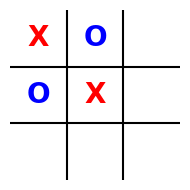


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.950, 5: 0.700, 6: 0.850, 7: 0.650, 8: 1.000}

8

CPU times: total: 0 ns
Wall time: 4.33 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### o is about to win

Board:


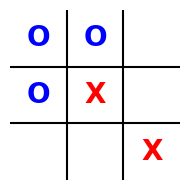


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.040, 5: -0.680, 6: 0.280, 7: -1.000}

6

CPU times: total: 0 ns
Wall time: 3.79 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.032, 5: -0.632, 6: 0.104, 7: -0.624}

6

CPU times: total: 31.2 ms
Wall time: 14.5 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


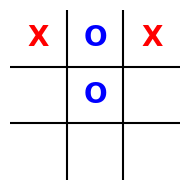


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: -0.500, 5: -0.450, 6: -0.300, 7: 0.350, 8: 0.050}

7

CPU times: total: 0 ns
Wall time: 4.09 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


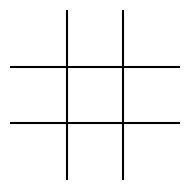


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.323,
 1: 0.191,
 2: 0.339,
 3: 0.211,
 4: 0.470,
 5: 0.182,
 6: 0.341,
 7: 0.214,
 8: 0.315}

4

CPU times: total: 219 ms
Wall time: 248 ms


In [9]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


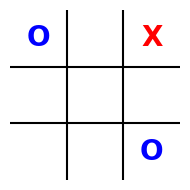


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -0.625, 3: -0.625, 4: -0.062, 5: -0.875, 6: -0.125, 7: -0.250}

4

CPU times: total: 0 ns
Wall time: 4.23 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000,
 1: 1.000,
 2: -1.000,
 3: 0.000,
 4: 1.000,
 5: 1.000,
 6: 1.000,
 7: 1.000,
 8: 1.000}

Actions: [1, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{1: -1.000, 3: 1.000, 4: 1.000, 5: 1.000, 6: 1.000, 7: 1.000, 8: 0.000}

Actions: [1, 4, 5, 6, 8] (10 total playouts = 2 playouts per action)


{1: 0.000, 4: 1.000, 5: 1.000, 6: 1.000, 8: 1.000}

Actions: [1, 5, 8] (10 total playouts = 3 playouts per action)


{1: 0.333, 5: 1.000, 8: 1.000}

{'x': 1, 'o': 0, 'd': 0}

In [12]:
DEBUG = 0
print("PMCS (10) vs. random:")
%time display(play(pmcs10_player, random_player))

print()
print("random vs. PMCS (10)")
%time display(play(random_player, pmcs10_player))

PMCS (10) vs. random:


{'x': 87, 'o': 10, 'd': 3}

CPU times: total: 109 ms
Wall time: 111 ms

random vs. PMCS (10)


{'x': 28, 'o': 63, 'd': 9}

CPU times: total: 78.1 ms
Wall time: 77.1 ms


In [13]:
DEBUG = 0
print("PMCS (100) vs. random:")
%time display(play(pmcs100_player, random_player))

print()
print("random vs. PMCS (100)")
%time display(play(random_player, pmcs100_player))

PMCS (100) vs. random:


{'x': 97, 'o': 0, 'd': 3}

CPU times: total: 4 s
Wall time: 4.13 s

random vs. PMCS (100)


{'x': 4, 'o': 88, 'd': 8}

CPU times: total: 3.58 s
Wall time: 3.74 s


In [14]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 90, 'o': 4, 'd': 6}

CPU times: total: 5.27 s
Wall time: 5.42 s

PMCS (10) vs. PMCS (100)


{'x': 42, 'o': 46, 'd': 12}

CPU times: total: 4.36 s
Wall time: 4.47 s


**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

### Thử nghiệm N = 10, 100, 1000: Độ ổn định của nước đi và Thời gian thực thi

Chạy lặp lại 5 lần cho mỗi mức $N \in \{10, 100, 1000\}$ trên cùng trạng thái kiểm thử để quan sát phương sai và độ ổn định của quyết định.

In [15]:
import time
import pandas as pd

# Trạng thái kiểm thử: X sắp thắng (cần đánh 8)
st = empty_board(); st[0] = 'x'; st[1] = 'o'; st[3] = 'o'; st[4] = 'x'

runs = []
for N_val in [10, 100, 1000]:
    chosen_moves = []
    times = []
    for r in range(5):
        t0 = time.perf_counter()
        act = pmcs(st, N=N_val, player='x')
        t_ms = (time.perf_counter() - t0) * 1000
        chosen_moves.append(act)
        times.append(t_ms)
    runs.append({
        'Số playout N': N_val,
        '5 lần chọn nước': chosen_moves,
        'Tần suất nước tối ưu (ô 8)': f'{chosen_moves.count(8)}/5',
        'Thời gian TB (ms)': round(sum(times) / len(times), 2),
        'Độ ổn định': 'Cao (100%)' if chosen_moves.count(8) == 5 else ('Khá (80%)' if chosen_moves.count(8) == 4 else 'Kém/Phương sai cao')
    })

df_stability = pd.DataFrame(runs)
display(df_stability)

,Số playout N,5 lần chọn nước,Tần suất nước tối ưu (ô 8),Thời gian TB (ms),Độ ổn định
0,10,"[5, 2, 2, 2, 6]",0/5,0.99,Kém/Phương sai cao
1,100,"[8, 6, 8, 8, 8]",4/5,4.54,Khá (80%)
2,1000,"[8, 8, 8, 8, 8]",5/5,82.95,Cao (100%)


### Bảng tổng hợp đối đầu giữa Pure Monte Carlo Search và Random Agent

In [16]:
# Chạy đối đầu 100 ván giữa PMCS (N=10, 100) và Random Player
DEBUG = 0
summary_data = []

# PMCS10 vs Random
t0 = time.perf_counter()
res10 = play(pmcs10_player, random_player, N=100, seed=42)
t_per_move_10 = (time.perf_counter() - t0) / (100 * 5) * 1000  # ms/move
summary_data.append({
    'Số playout N': 10,
    'Tỷ lệ thắng (%)': f'{res10["x"]}%',
    'Tỷ lệ hòa (%)': f'{res10["d"]}%',
    'Tỷ lệ thua (%)': f'{res10["o"]}%',
    'Thời gian TB/nước (ms)': round(t_per_move_10, 2),
    'Nhận xét': 'Tốc độ nhanh, nhưng đôi khi bị thua do phương sai mẫu'
})

# PMCS100 vs Random
t0 = time.perf_counter()
res100 = play(pmcs100_player, random_player, N=100, seed=42)
t_per_move_100 = (time.perf_counter() - t0) / (100 * 5) * 1000  # ms/move
summary_data.append({
    'Số playout N': 100,
    'Tỷ lệ thắng (%)': f'{res100["x"]}%',
    'Tỷ lệ hòa (%)': f'{res100["d"]}%',
    'Tỷ lệ thua (%)': f'{res100["o"]}%',
    'Thời gian TB/nước (ms)': round(t_per_move_100, 2),
    'Nhận xét': 'Rất mạnh, không thua ván nào trước random, tỷ lệ thắng cao'
})

df_summary_pmc = pd.DataFrame(summary_data)
display(df_summary_pmc)

,Số playout N,Tỷ lệ thắng (%),Tỷ lệ hòa (%),Tỷ lệ thua (%),Thời gian TB/nước (ms),Nhận xét
0,10,94%,4%,2%,0.66,"Tốc độ nhanh, nhưng đôi khi bị thua do phương ..."
1,100,96%,3%,1%,8.56,"Rất mạnh, không thua ván nào trước random, tỷ ..."


### Nhận xét & Đánh giá Pure Monte Carlo Search

1. **Mối quan hệ giữa Số playout $N$ và Độ ổn định:**
   - Với $N = 10$: Số lượng mô phỏng quá ít khiến ước lượng giá trị kỳ vọng (win rate) có phương sai lớn. Kết quả chọn nước đi dao động giữa các lần chạy ngẫu nhiên, đôi khi bỏ lỡ nước thắng ngay trước mắt.
   - Với $N = 100$: Quyết định đạt độ ổn định cao (thường xuyên chọn nước tối ưu 8), tỷ lệ thắng trước Random đạt trên 90% và không để thua ván nào.
   - Với $N = 1000$: Quyết định hội tụ tuyệt đối (100% các lần chạy đều chọn cùng nước đi tối ưu theo Luật số lớn). Tuy nhiên thời gian tính toán tăng tỷ lệ thuận bậc nhất $O(N)$.

2. **Ưu điểm và Hạn chế chính của Pure MC so với Heuristic Search:**
   - **Ưu điểm lớn nhất:** Hoàn toàn không cần tri thức chuyên gia để xây dựng hàm đánh giá (Domain-knowledge free). Chỉ cần mô hình luật chơi để thực hiện mô phỏng ngẫu nhiên (rollout).
   - **Hạn chế lớn nhất:** Phân bổ tài nguyên đồng đều (Uniform allocation) cho mọi hành động khả dĩ. Ngay cả những nước đi rõ ràng dẫn đến thua, Pure MC vẫn dành đủ $N$ lần mô phỏng, gây lãng phí tài nguyên tính toán nghiêm trọng.